# Feed-Forward Neural Network with Sentence Transformer Embeddings

Train and evaluate a feed-forward neural network using pretrained sentence embeddings.

In [23]:
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import random

import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras

import json

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    ConfusionMatrixDisplay,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score,
    roc_curve,
)

## Load Data and Embeddings

Load the train, validation, and test datasets along with their saved sentence embeddings.

In [2]:
PROJECT_ROOT = Path("../..")

DATA_DIR = PROJECT_ROOT / "data"
PROCESSED_DIR = DATA_DIR / "processed"

MODELS_DIR = PROJECT_ROOT / "models"
EMBEDDINGS_MODEL_DIR = MODELS_DIR / "embeddings"

In [4]:
train_df = pd.read_csv(PROCESSED_DIR / "train.csv")
validation_df = pd.read_csv(PROCESSED_DIR / "validation.csv")
test_df = pd.read_csv(PROCESSED_DIR / "test.csv")

X_train = np.load(
    EMBEDDINGS_MODEL_DIR / "train_embeddings.npy"
)

X_validation = np.load(
    EMBEDDINGS_MODEL_DIR / "validation_embeddings.npy"
)

X_test = np.load(
    EMBEDDINGS_MODEL_DIR / "test_embeddings.npy"
)

y_train = train_df["target"].to_numpy()
y_validation = validation_df["target"].to_numpy()
y_test = test_df["target"].to_numpy()

In [5]:
print("Train:", X_train.shape, y_train.shape)
print("Validation:", X_validation.shape, y_validation.shape)
print("Test:", X_test.shape, y_test.shape)

assert len(X_train) == len(y_train)
assert len(X_validation) == len(y_validation)
assert len(X_test) == len(y_test)

Train: (58823, 384) (58823,)
Validation: (12611, 384) (12611,)
Test: (12632, 384) (12632,)


## Build the Neural Network

Define a feed-forward neural network for the 384-dimensional sentence embeddings.

In [10]:
RANDOM_STATE = 42

random.seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)
tf.random.set_seed(RANDOM_STATE)

In [16]:
model = keras.Sequential([
    keras.layers.Input(shape=(384,)),

    keras.layers.Dense(64, activation="relu"),
    keras.layers.Dropout(0.3),

    keras.layers.Dense(32, activation="relu"),
    keras.layers.Dropout(0.3),

    keras.layers.Dense(1, activation="sigmoid")
])

model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_3 (Dense)                 │ (None, 64)             │        24,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 26,753 (104.50 KB)

 Trainable params: 26,753 (104.50 KB)

 Non-trainable params: 0 (0.00 B)

In [17]:
model.compile(
    optimizer=keras.optimizers.Adam(
    learning_rate=0.0001
    ),
    loss="binary_crossentropy",
    metrics=[
    "accuracy",
    keras.metrics.AUC(name="auc")
]
)

In [18]:
early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=2,
    restore_best_weights=True
)

## Balance class weights

In [19]:
from sklearn.utils.class_weight import compute_class_weight
import numpy as np

classes = np.unique(y_train)

weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train
)

class_weights = dict(zip(classes, weights))

print("Class weights:", class_weights)

Class weights: {np.int64(0): np.float64(0.7348465920447731), np.int64(1): np.float64(1.5645247087611043)}


## Train the Model

Train the neural network using the embedding features and monitor validation loss with early stopping.

In [20]:
history = model.fit(
    X_train,
    y_train,
    validation_data=(
        X_validation,
        y_validation
    ),
    epochs=50,
    batch_size=64,
    class_weight=class_weights,
    callbacks=[early_stopping],
    verbose=2
)

Epoch 1/50
920/920 - 1s - 1ms/step - accuracy: 0.6541 - auc: 0.7589 - loss: 0.6294 - val_accuracy: 0.7777 - val_auc: 0.8720 - val_loss: 0.5112
Epoch 2/50
920/920 - 0s - 508us/step - accuracy: 0.7881 - auc: 0.8736 - loss: 0.4558 - val_accuracy: 0.8114 - val_auc: 0.9011 - val_loss: 0.4125
Epoch 3/50
920/920 - 0s - 515us/step - accuracy: 0.8113 - auc: 0.8976 - loss: 0.4058 - val_accuracy: 0.8274 - val_auc: 0.9126 - val_loss: 0.3807
Epoch 4/50
920/920 - 0s - 502us/step - accuracy: 0.8246 - auc: 0.9075 - loss: 0.3858 - val_accuracy: 0.8354 - val_auc: 0.9192 - val_loss: 0.3679
Epoch 5/50
920/920 - 0s - 513us/step - accuracy: 0.8325 - auc: 0.9145 - loss: 0.3715 - val_accuracy: 0.8405 - val_auc: 0.9239 - val_loss: 0.3565
Epoch 6/50
920/920 - 0s - 511us/step - accuracy: 0.8372 - auc: 0.9199 - loss: 0.3600 - val_accuracy: 0.8440 - val_auc: 0.9279 - val_loss: 0.3485
Epoch 7/50
920/920 - 0s - 507us/step - accuracy: 0.8436 - auc: 0.9246 - loss: 0.3497 - val_accuracy: 0.8472 - val_auc: 0.9315 - val_

## Evaluate on Validation Data

Evaluate the embedding-based neural network on the validation set using accuracy, precision, recall, macro F1, and ROC-AUC.

In [21]:
val_probs = model.predict(
    X_validation
).ravel()

val_predictions = (
    val_probs >= 0.5
).astype(int)

print(
    "Validation Accuracy:",
    accuracy_score(
        y_validation,
        val_predictions
    )
)

print(
    "Validation Macro Precision:",
    precision_score(
        y_validation,
        val_predictions,
        average="macro"
    )
)

print(
    "Validation Macro Recall:",
    recall_score(
        y_validation,
        val_predictions,
        average="macro"
    )
)

print(
    "Validation Macro F1:",
    f1_score(
        y_validation,
        val_predictions,
        average="macro"
    )
)

print(
    "Validation ROC-AUC:",
    roc_auc_score(
        y_validation,
        val_probs
    )
)

print()

print(
    classification_report(
        y_validation,
        val_predictions,
        target_names=[
            "Human",
            "ChatGPT"
        ]
    )
)

395/395 ━━━━━━━━━━━━━━━━━━━━ 0s 207us/step
Validation Accuracy: 0.9149948457695662
Validation Macro Precision: 0.8981853147706174
Validation Macro Recall: 0.910450892517241
Validation Macro F1: 0.9038294606439388
Validation ROC-AUC: 0.9716975890845038

              precision    recall  f1-score   support

       Human       0.95      0.92      0.94      8578
     ChatGPT       0.85      0.90      0.87      4033

    accuracy                           0.91     12611
   macro avg       0.90      0.91      0.90     12611
weighted avg       0.92      0.91      0.92     12611



Validation Confusion Matrix:
[[7918  660]
 [ 412 3621]]


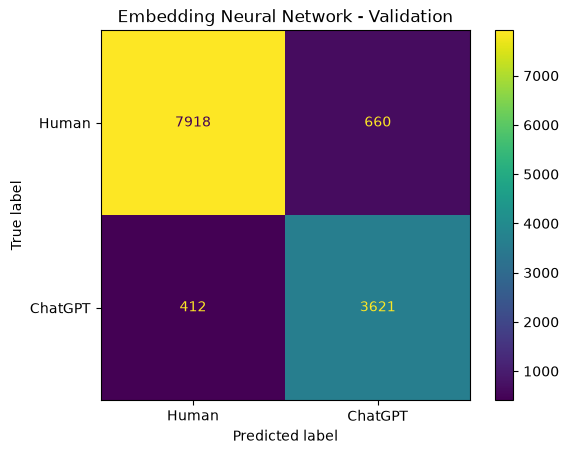

In [24]:
val_cm = confusion_matrix(
    y_validation,
    val_predictions
)

print(
    "Validation Confusion Matrix:"
)
print(val_cm)

ConfusionMatrixDisplay(
    confusion_matrix=val_cm,
    display_labels=[
        "Human",
        "ChatGPT"
    ]
).plot()

plt.title(
    "Embedding Neural Network - Validation"
)

plt.show()

## Evaluate on Test Data

Evaluate the final neural network on the held-out test set using the same performance metrics.

In [25]:
test_probs = model.predict(
    X_test
).ravel()

test_predictions = (
    test_probs >= 0.5
).astype(int)

print(
    "Test Accuracy:",
    accuracy_score(
        y_test,
        test_predictions
    )
)

print(
    "Test Macro Precision:",
    precision_score(
        y_test,
        test_predictions,
        average="macro"
    )
)

print(
    "Test Macro Recall:",
    recall_score(
        y_test,
        test_predictions,
        average="macro"
    )
)

print(
    "Test Macro F1:",
    f1_score(
        y_test,
        test_predictions,
        average="macro"
    )
)

print(
    "Test ROC-AUC:",
    roc_auc_score(
        y_test,
        test_probs
    )
)

print()

print(
    classification_report(
        y_test,
        test_predictions,
        target_names=[
            "Human",
            "ChatGPT"
        ]
    )
)

395/395 ━━━━━━━━━━━━━━━━━━━━ 0s 185us/step
Test Accuracy: 0.9220234325522483
Test Macro Precision: 0.9059783031974616
Test Macro Recall: 0.9191622961030365
Test Macro F1: 0.9120118425045556
Test ROC-AUC: 0.9764067646980916

              precision    recall  f1-score   support

       Human       0.96      0.93      0.94      8579
     ChatGPT       0.86      0.91      0.88      4053

    accuracy                           0.92     12632
   macro avg       0.91      0.92      0.91     12632
weighted avg       0.92      0.92      0.92     12632



Test Confusion Matrix:
[[7954  625]
 [ 360 3693]]


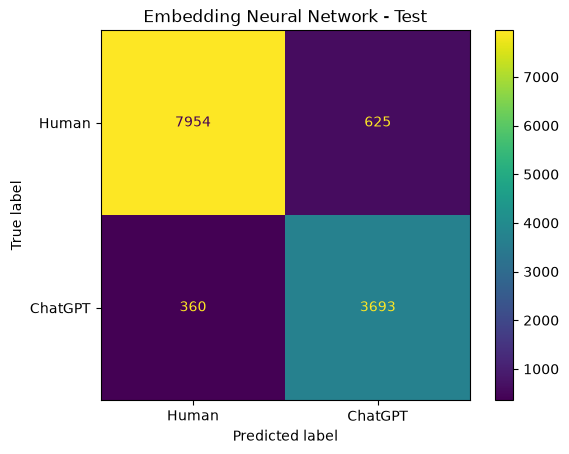

In [26]:
test_cm = confusion_matrix(
    y_test,
    test_predictions
)

print(
    "Test Confusion Matrix:"
)
print(test_cm)

ConfusionMatrixDisplay(
    confusion_matrix=test_cm,
    display_labels=[
        "Human",
        "ChatGPT"
    ]
).plot()

plt.title(
    "Embedding Neural Network - Test"
)

plt.show()

## ROC Curve

Visualize the model's ability to distinguish between human and ChatGPT-generated text across classification thresholds.

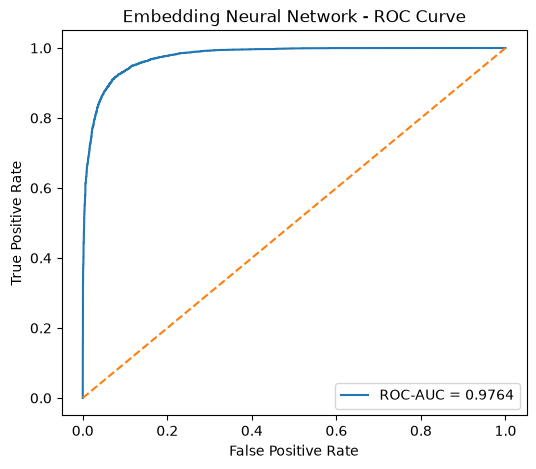

In [27]:
from sklearn.metrics import roc_curve

fpr, tpr, thresholds = roc_curve(
    y_test,
    test_probs
)

plt.figure(figsize=(6, 5))

plt.plot(
    fpr,
    tpr,
    label=f"ROC-AUC = {roc_auc_score(y_test, test_probs):.4f}"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Embedding Neural Network - ROC Curve")
plt.legend()
plt.show()

## Save Model

Save the trained embedding-based neural network model for reuse and comparison.

In [28]:
neural_network_path = (
    EMBEDDINGS_MODEL_DIR
    / "feedforward_neural_network_embeddings.keras"
)

model.save(
    neural_network_path
)

print("Saved:")
print(neural_network_path)

Saved:
../../models/embeddings/feedforward_neural_network_embeddings.keras
